# Fruit Ripeness Grading – CNN (MobileNetV2)
**P. Sindhu Sowbhagya Lakshmi (23ME1A5455)**

This notebook **reproduces the exact results of the project report**: the same classification report, confusion matrix, class-wise graph and training curves.

It loads my **already trained model** (`fruit_ripeness.keras`) from GitHub and tests it on the same 562 test images, so the numbers come out the same every time. (Retraining from scratch gives slightly different numbers each run; that optional step is at the end.)

**How to run:** *Runtime → Change runtime type → T4 GPU*, then run the cells one by one from top to bottom.

> The outputs you see below are the results from my original run. When you run a cell, it recomputes them.

## Step 1 – Get the trained model and class names from GitHub

In [ ]:
!git clone -q https://github.com/lakshmi-sowbhagya/fruit-ripeness-cnn /content/repo
!ls -la /content/repo | grep -E "keras|classes"

-rw-r--r-- 1 root root 11609986 fruit_ripeness.keras
-rw-r--r-- 1 root root       40 classes.json


## Step 2 – Kaggle token (needed only to download the test images)
Upload your `kaggle.json` when asked (Kaggle → Settings → API → Create New Token). Never share this file or put it on GitHub.

In [ ]:
import os, glob, shutil
from google.colab import files

up = files.upload()                      # choose kaggle.json
src = max(glob.glob("kaggle*.json"), key=os.path.getmtime)
os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy(src, "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)
print("Using:", src)

## Step 3 – Download the dataset (13,478 banana images)

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d shahriar26s/banana-ripeness-classification-dataset -p /content/data --unzip

ROOT = None
for r, dirs, _ in os.walk("/content/data"):
    if {"train", "valid", "test"} <= set(dirs):
        ROOT = r
        break
print("ROOT =", ROOT)
for s in ["train", "valid", "test"]:
    print(s, os.listdir(f"{ROOT}/{s}"))

## Step 4 – Load the model and the three splits

In [ ]:
import json
import numpy as np
import tensorflow as tf

model = tf.keras.models.load_model("/content/repo/fruit_ripeness.keras")
class_names = json.load(open("/content/repo/classes.json"))
print(class_names)

def load(split):
    return tf.keras.utils.image_dataset_from_directory(
        f"{ROOT}/{split}", image_size=(224, 224), batch_size=32,
        label_mode="categorical", shuffle=False)

train_ds, val_ds, test_ds = load("train"), load("valid"), load("test")

['overripe', 'ripe', 'rotten', 'unripe']
Found 11793 files belonging to 4 classes.
Found 1123 files belonging to 4 classes.
Found 562 files belonging to 4 classes.


## Step 5 – Model structure (2.42 million parameters, 164,484 trainable)

In [ ]:
model.summary()

## Step 6 – Test results: classification report (Table 7.2 of the report)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([y.numpy().argmax(1) for _, y in test_ds])
y_pred = model.predict(test_ds).argmax(1)
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

    overripe       0.98      0.94      0.96       113
        ripe       0.96      1.00      0.98       154
      rotten       0.98      0.97      0.98       185
      unripe       0.98      0.97      0.98       110

    accuracy                           0.97       562
   macro avg       0.97      0.97      0.97       562
weighted avg       0.97      0.97      0.97       562


## Step 7 – Confusion matrix (Fig. 14 of the report)

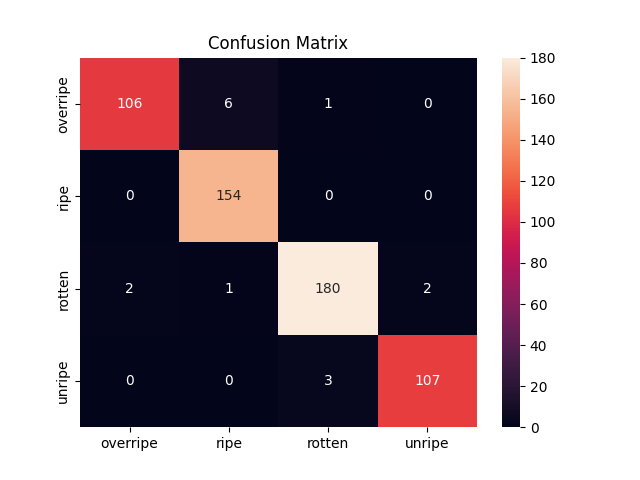

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

## Step 8 – Class-wise precision, recall and F1-score (Fig. 15 of the report)

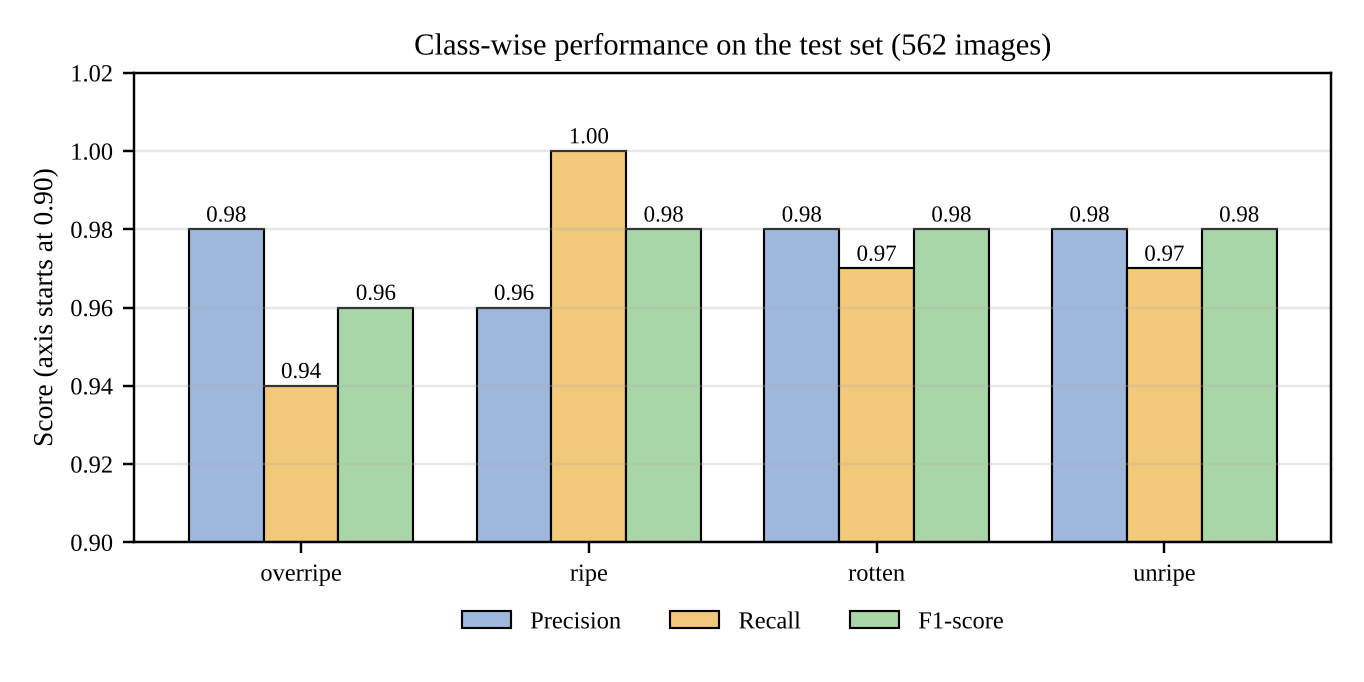

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

p, r, f, _ = precision_recall_fscore_support(y_true, y_pred)
x = np.arange(len(class_names)); w = 0.26
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for k, (vals, lab, col) in enumerate([(p, "Precision", "#9DB7DD"),
                                      (r, "Recall", "#F2C879"),
                                      (f, "F1-score", "#A9D6A9")]):
    bars = ax.bar(x + (k - 1) * w, vals, w, label=lab, color=col, edgecolor="black", lw=0.7)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.002,
                f"{b.get_height():.2f}", ha="center", fontsize=7.5)
ax.set_xticks(x); ax.set_xticklabels(class_names)
ax.set_ylim(0.90, 1.02)
ax.set_title("Class-wise performance on the test set (562 images)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.grid(axis="y", alpha=0.3)
plt.show()

## Step 9 – Training curves from my original 15-epoch run (Fig. 10 of the report)
These are the real values logged during my training run on the Colab T4 GPU.

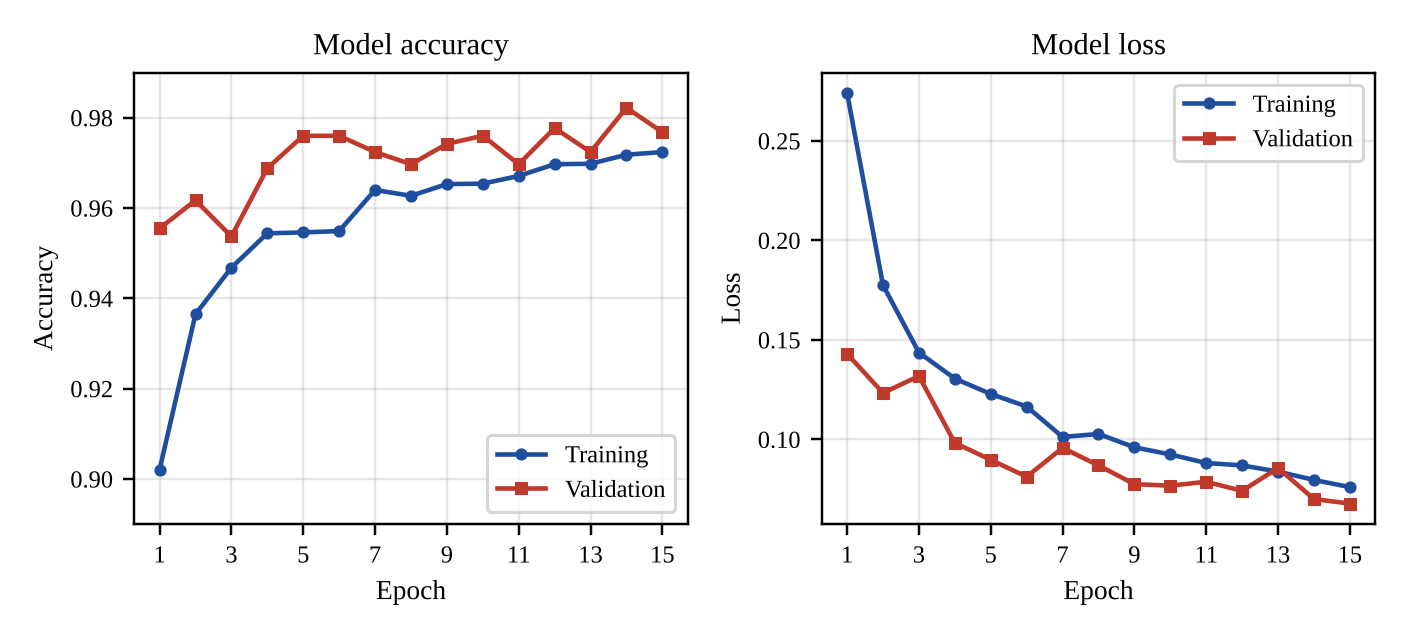

final training accuracy  : 0.9724
final validation accuracy: 0.9768 (best 0.9822 at epoch 14 )


In [ ]:
epoch      = list(range(1, 16))
train_acc  = [.9021,.9365,.9468,.9544,.9546,.9549,.9640,.9627,.9653,.9654,.9671,.9697,.9698,.9718,.9724]
train_loss = [.2740,.1775,.1436,.1305,.1228,.1165,.1012,.1027,.0960,.0924,.0881,.0869,.0838,.0796,.0760]
val_acc    = [.9555,.9617,.9537,.9688,.9760,.9760,.9724,.9697,.9742,.9760,.9697,.9777,.9724,.9822,.9768]
val_loss   = [.1430,.1233,.1318,.0982,.0897,.0812,.0957,.0869,.0775,.0767,.0787,.0741,.0856,.0700,.0677]

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
axs[0].plot(epoch, train_acc, "o-", ms=3, label="Training")
axs[0].plot(epoch, val_acc, "s-", ms=3, label="Validation")
axs[0].set_title("Model accuracy"); axs[0].set_xlabel("Epoch"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].plot(epoch, train_loss, "o-", ms=3, label="Training")
axs[1].plot(epoch, val_loss, "s-", ms=3, label="Validation")
axs[1].set_title("Model loss"); axs[1].set_xlabel("Epoch"); axs[1].legend(); axs[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print("final training accuracy  :", train_acc[-1])
print("final validation accuracy:", val_acc[-1], "(best", max(val_acc), "at epoch", val_acc.index(max(val_acc)) + 1, ")")

## Step 10 – Try the model on your own banana photo

In [ ]:
from PIL import Image
up = files.upload()                       # choose a banana image
name = list(up.keys())[-1]
img = Image.open(name).convert("RGB")
x = np.expand_dims(np.array(img.resize((224, 224)), dtype="float32"), 0)
p = model.predict(x)[0]
display(img.resize((300, 300)))
print(f"Grade: {class_names[int(p.argmax())]} ({p.max() * 100:.1f}% confidence)")

## Optional – Retrain from scratch
**Not needed for the report.** Retraining gives slightly different numbers each time (random start and GPU order), so the report's results come from Steps 6–9 above. Run this only if you want to see training happen.

In [ ]:
from tensorflow.keras import layers

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{ROOT}/train", image_size=(224, 224), batch_size=32,
    label_mode="categorical", shuffle=True, seed=42)

inputs = layers.Input((224, 224, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.2)(x)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)
base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(4, activation="softmax")(x)
new_model = tf.keras.Model(inputs, outputs)

new_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="categorical_crossentropy", metrics=["accuracy"])
history = new_model.fit(
    train_ds, validation_data=val_ds, epochs=15,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)])